# Linear and Logistic Regression

The plan is deliberately narrow. We build **one** fitting function, and then use it twice without
changing a line of it:

- **Linear regression** on the diabetes data: predict how far a patient's disease progresses in a
  year, from ten measurements taken at the start.
- **Logistic regression** on the breast cancer data: decide whether a tumour is malignant or benign
  from thirty measurements of a cell nucleus.

The only difference between the two is whether the linear output passes through a sigmoid. That is
the point of the week, so the code is arranged to make it hard to miss.

Everything is written in plain Python — lists, loops and `math`. No NumPy, no scikit-learn. Array
libraries are what you would reach for in practice, but they hide the arithmetic behind operators
like `X @ w`, and the arithmetic is exactly what is being taught. Here every sum is a sum you can
point at. Matplotlib is used for pictures only, never for computation.

## Setup

In [1]:
from __future__ import annotations

import csv
import math
import random
from dataclasses import dataclass, field
from typing import Callable, Sequence

import matplotlib.pyplot as plt

Vector = list[float]
Matrix = list[Vector]
Hypothesis = Callable[[float], float]
LossFunction = Callable[[Vector, Vector], float]

SEED = 5

## The pieces

`Vector` is a list of numbers and `Matrix` is a list of rows. Those two aliases are the whole data
model, and the type annotations throughout say which of the two every function expects.

Two operations carry all the arithmetic in this notebook.

In [2]:
def dot(a: Vector, b: Vector) -> float:
    return sum(ai * bi for ai, bi in zip(a, b))


def transpose(X: Matrix) -> Matrix:
    return [list(column) for column in zip(*X)]


def mean(values: Sequence[float]) -> float:
    return sum(values) / len(values)


def std(values: Sequence[float]) -> float:
    mu = mean(values)
    return math.sqrt(sum((value - mu) ** 2 for value in values) / len(values))


def linspace(start: float, stop: float, count: int) -> Vector:
    step = (stop - start) / (count - 1)
    return [start + step * i for i in range(count)]

`dot` is worth a second look, because it appears in both directions of the algorithm:

- **Forwards**, a prediction is `dot(weights, row)` — one dot product per *row* of the data.
- **Backwards**, a gradient is `dot(errors, column)` — one dot product per *column*.

That symmetry is the entire fitting loop, and it is visible here in a way `X @ w` does not make
visible.

### The hypothesis

A **hypothesis** turns the linear output `w · x + b` into a prediction. `identity` leaves it alone
and we are doing regression; `sigmoid` squashes it into `(0, 1)` and we are doing classification.

The sigmoid is written in two branches. The textbook form `1 / (1 + exp(-z))` overflows for very
negative `z`, and plain Python raises `OverflowError` where NumPy would quietly hand back `inf`.
Both branches are algebraically the same function; each one is used where its exponential is small.

In [3]:
def identity(z: float) -> float:
    return z


def sigmoid(z: float) -> float:
    if z >= 0.0:
        return 1.0 / (1.0 + math.exp(-z))
    exp_z = math.exp(z)
    return exp_z / (1.0 + exp_z)

### The model

A fitted model is three things: the weights, the bias, and the hypothesis that shapes the output.
Bundling them means a model can be handed around and asked for predictions without carrying three
loose variables alongside it.

In [4]:
@dataclass
class Model:
    weights: Vector
    bias: float
    hypothesis: Hypothesis = identity

    @classmethod
    def zeros(cls, n_features: int, hypothesis: Hypothesis = identity) -> "Model":
        return cls(weights=[0.0] * n_features, bias=0.0, hypothesis=hypothesis)

    def predict_one(self, x: Vector) -> float:
        return self.hypothesis(dot(self.weights, x) + self.bias)

    def predict(self, X: Matrix) -> Vector:
        return [self.predict_one(row) for row in X]

### Losses and scores

Two different jobs, easy to confuse:

- A **loss** is what gradient descent minimises. It has to be differentiable, and its absolute
  value is not meant to be interpretable.
- A **score** is what you report. It does not have to be differentiable, and it does have to be
  interpretable.

`mse` and `cross_entropy` are losses. `rmse`, `r2` and `accuracy` are scores.

`cross_entropy` clips the probability away from 0 and 1 before taking the logarithm, because
`log(0)` is undefined and a saturated sigmoid will hand you exactly 0.0 in floating point.

In [5]:
def mse(y: Vector, y_hat: Vector) -> float:
    return sum((actual - predicted) ** 2 for actual, predicted in zip(y, y_hat)) / len(y)


def rmse(y: Vector, y_hat: Vector) -> float:
    return math.sqrt(mse(y, y_hat))


def cross_entropy(y: Vector, p: Vector, eps: float = 1e-12) -> float:
    total = 0.0
    for actual, predicted in zip(y, p):
        clipped = min(max(predicted, eps), 1.0 - eps)
        total += actual * math.log(clipped) + (1.0 - actual) * math.log(1.0 - clipped)
    return -total / len(y)


def r2(y: Vector, y_hat: Vector) -> float:
    y_bar = mean(y)
    ss_res = sum((actual - predicted) ** 2 for actual, predicted in zip(y, y_hat))
    ss_tot = sum((actual - y_bar) ** 2 for actual in y)
    return 1.0 - ss_res / ss_tot


def accuracy(y: Vector, p: Vector, threshold: float = 0.5) -> float:
    hits = sum(1 for actual, predicted in zip(y, p) if actual == float(predicted >= threshold))
    return hits / len(y)

#### R², in code and in words

`r2` deserves unpacking, because it is the number quoted for every regression below and it is not
a percentage of anything obvious.

It compares two sums of squared errors:

- `ss_res` — how much your model missed by.
- `ss_tot` — how much the **dumbest possible model** missed by, where the dumbest possible model
  ignores the features entirely and predicts the mean of `y` every single time.

The ratio `ss_res / ss_tot` is your error as a fraction of the baseline's error, and R² is one
minus that, so bigger is better. Three values to anchor it:

| R² | meaning |
| --- | --- |
| `1.0` | every prediction exact, `ss_res = 0` |
| `0.0` | exactly as good as always guessing the mean |
| `< 0` | **worse than guessing the mean** |

The last row surprises people. R² is not a square and nothing stops it going negative — it does so
whenever your model is actively worse than a flat line, which is possible on a test set and
happens often with a bad fit.

Why report it at all when RMSE is in the units of the target and easier to picture? Because RMSE
alone cannot tell you whether a number is any good. An RMSE of 53 on the diabetes data means
nothing until you know the target ranges from 25 to 346. R² does that comparison for you, which is
what makes it portable across problems.

A small worked example, three points, which you can check by hand:

In [6]:
demo_y = [2.0, 3.0, 5.0]
demo_fitted = [1.8333, 3.3333, 4.8333]
demo_baseline = [mean(demo_y)] * 3

print(f"mean of y                 {mean(demo_y):.4f}")
print(f"ss_tot (baseline error)   {sum((v - mean(demo_y)) ** 2 for v in demo_y):.4f}")
print(f"ss_res (model error)      {sum((a - b) ** 2 for a, b in zip(demo_y, demo_fitted)):.4f}")
print()
print(f"R2 of the fitted line     {r2(demo_y, demo_fitted):.4f}")
print(f"R2 of the baseline        {r2(demo_y, demo_baseline):.4f}")
print(f"R2 of a worse-than-flat   {r2(demo_y, [5.0, 1.0, 2.0]):.4f}")

mean of y                 3.3333
ss_tot (baseline error)   4.6667
ss_res (model error)      0.1667

R2 of the fitted line     0.9643
R2 of the baseline        0.0000
R2 of a worse-than-flat   -3.7143


The fitted line leaves 1/28 of the baseline's error, so R² is 27/28. The baseline scores exactly
zero by construction — it *is* the thing R² measures against. And a deliberately terrible set of
predictions goes negative.

### Standardising

Subtract each column's mean, divide by its standard deviation. Written as a small class rather
than a function for one reason: the statistics must be learned on the training set and then
**applied unchanged** to the test set. Keeping `means` and `stds` in an object makes that hard to
get wrong, where two loose variables invite recomputing them on the test data by accident.

In [7]:
@dataclass
class Standardiser:
    means: Vector
    stds: Vector

    @classmethod
    def fit(cls, X: Matrix) -> "Standardiser":
        columns = transpose(X)
        return cls(means=[mean(c) for c in columns], stds=[std(c) or 1.0 for c in columns])

    def transform(self, X: Matrix) -> Matrix:
        return [
            [(value - mu) / sigma for value, mu, sigma in zip(row, self.means, self.stds)]
            for row in X
        ]

### The fitting function

The update rule from the README, transcribed:

    wᵢ ← wᵢ + α Σⱼ (yⱼ - h(xⱼ))·xⱼ,ᵢ

with one adjustment: the sum is divided by the number of rows, which makes the useful range of
learning rates independent of how much data there is. The `1/n` could equally be folded into `α`.

Read `errors = [actual - predicted ...]` as the heart of it. Every weight then moves by
`dot(errors, column)` — the error, weighted by how much that feature contributed to it.

`diverged` is a real outcome, not an error case. Too large a learning rate sends the weights to
infinity, and in plain Python that surfaces as an `OverflowError` or a `nan` rather than NumPy's
silent `inf`. We catch it, stop early, and report it, because the sweep below *needs* to diverge
on purpose to find the largest learning rate that does not.

In [8]:
@dataclass
class FitResult:
    model: Model
    history: list[float] = field(default_factory=list)
    diverged: bool = False


def fit(
    X: Matrix,
    y: Vector,
    hypothesis: Hypothesis = identity,
    loss_fn: LossFunction = mse,
    lr: float = 0.1,
    n_iters: int = 1000,
) -> FitResult:
    n_rows = len(X)
    columns = transpose(X)
    model = Model.zeros(len(columns), hypothesis)
    history: list[float] = []

    for _ in range(n_iters):
        try:
            predictions = model.predict(X)
            loss = loss_fn(y, predictions)
        except OverflowError:
            return FitResult(model, history, diverged=True)
        if not math.isfinite(loss):
            return FitResult(model, history, diverged=True)
        history.append(loss)

        errors = [actual - predicted for actual, predicted in zip(y, predictions)]
        for j, column in enumerate(columns):
            model.weights[j] += lr * dot(errors, column) / n_rows
        model.bias += lr * sum(errors) / n_rows

    return FitResult(model, history, diverged=False)

## Part 1 — does it actually find the minimum

Before trusting it on real data, check it against an answer we can compute exactly. For a straight
line through points the weights that minimise squared error can be written down in closed form, so
we have something to compare with.

In [9]:
rng = random.Random(SEED)
X_demo: Matrix = [[rng.uniform(0.0, 1.0)] for _ in range(60)]
y_demo: Vector = [3.0 * row[0] + 2.0 + rng.gauss(0.0, 0.15) for row in X_demo]

xs = [row[0] for row in X_demo]
n = len(y_demo)
slope_exact = (n * dot(xs, y_demo) - sum(xs) * sum(y_demo)) / (n * dot(xs, xs) - sum(xs) ** 2)
intercept_exact = (sum(y_demo) - slope_exact * sum(xs)) / n
exact = Model(weights=[slope_exact], bias=intercept_exact)

result = fit(X_demo, y_demo, lr=0.5, n_iters=20000)

print(f"{'':<18}{'slope':>12}{'intercept':>12}{'loss':>12}")
print(f"{'closed form':<18}{slope_exact:>12.6f}{intercept_exact:>12.6f}{mse(y_demo, exact.predict(X_demo)):>12.6f}")
print(f"{'gradient descent':<18}{result.model.weights[0]:>12.6f}{result.model.bias:>12.6f}{result.history[-1]:>12.6f}")
print(f"\nthe data was generated from slope 3.0, intercept 2.0, plus noise")

                         slope   intercept        loss
closed form           3.083492    1.963170    0.031980
gradient descent      3.083492    1.963170    0.031980

the data was generated from slope 3.0, intercept 2.0, plus noise


Identical to six decimals. Gradient descent did not approximate the answer, it found it.

Two pictures. On the left the fitted line; on the right the loss at each step, on a log scale so
the early collapse and the long flat tail are both visible.

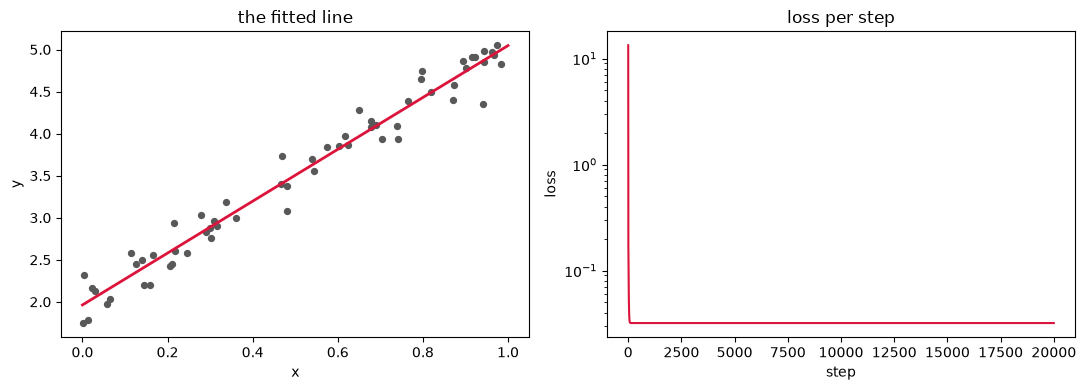

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.scatter(xs, y_demo, s=18, color="0.35")
grid = [0.0, 1.0]
ax1.plot(grid, [result.model.predict_one([g]) for g in grid], color="crimson", lw=2)
ax1.set_xlabel("x"), ax1.set_ylabel("y"), ax1.set_title("the fitted line")

ax2.plot(result.history, color="crimson")
ax2.set_yscale("log")
ax2.set_xlabel("step"), ax2.set_ylabel("loss"), ax2.set_title("loss per step")
fig.tight_layout()
plt.show()

### The loss surface

Fix the data and the loss becomes a function of the weights alone. With two weights that is a
surface, and fitting is the search for its lowest point.

The red path is gradient descent walking in from a deliberately bad starting point; the black cross
is the closed-form answer. The shape is a bowl — convex, one minimum, nowhere to get stuck. That is
a property of squared error with a linear model, and it is exactly what stops being true later in
the course.

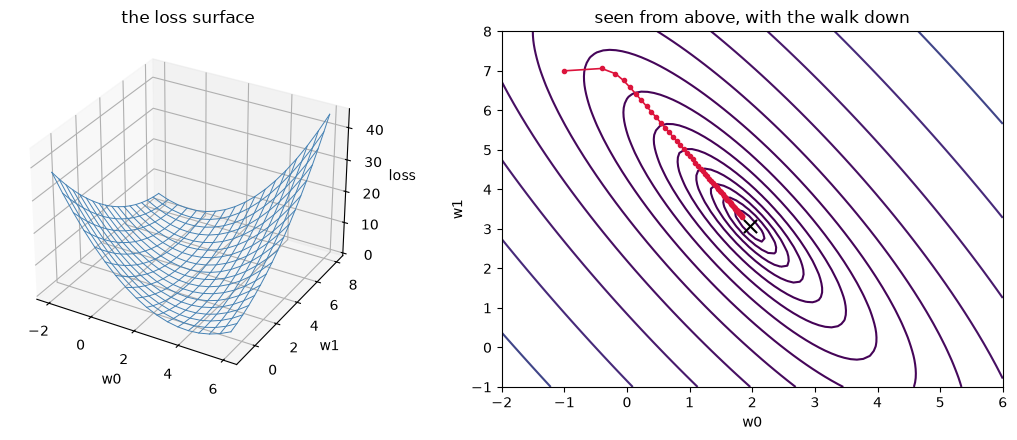

In [11]:
def loss_at(intercept: float, slope: float) -> float:
    return mse(y_demo, [slope * x + intercept for x in xs])


intercepts = linspace(-2.0, 6.0, 80)
slopes = linspace(-1.0, 8.0, 80)
grid_w0 = [[w0 for w0 in intercepts] for _ in slopes]
grid_w1 = [[w1 for _ in intercepts] for w1 in slopes]
surface = [[loss_at(w0, w1) for w0 in intercepts] for w1 in slopes]

wire_w0 = linspace(-2.0, 6.0, 18)
wire_w1 = linspace(-1.0, 8.0, 18)

walk = Model(weights=[7.0], bias=-1.0)
path = [(walk.bias, walk.weights[0])]
for _ in range(60):
    errors = [actual - predicted for actual, predicted in zip(y_demo, walk.predict(X_demo))]
    walk.weights[0] += 0.6 * dot(errors, xs) / len(xs)
    walk.bias += 0.6 * sum(errors) / len(xs)
    path.append((walk.bias, walk.weights[0]))

fig = plt.figure(figsize=(11, 4.5))

ax = fig.add_subplot(1, 2, 1, projection="3d")
for w1 in wire_w1:
    ax.plot(wire_w0, [w1] * len(wire_w0), [loss_at(w0, w1) for w0 in wire_w0],
            color="steelblue", lw=0.7)
for w0 in wire_w0:
    ax.plot([w0] * len(wire_w1), wire_w1, [loss_at(w0, w1) for w1 in wire_w1],
            color="steelblue", lw=0.7)
ax.set_xlabel("w0"), ax.set_ylabel("w1"), ax.set_zlabel("loss")
ax.set_title("the loss surface")

ax2 = fig.add_subplot(1, 2, 2)
ax2.contour(grid_w0, grid_w1, surface, levels=[0.05 * 1.7 ** k for k in range(16)], cmap="viridis")
ax2.plot([p[0] for p in path], [p[1] for p in path], "o-", color="crimson", ms=3, lw=1.2)
ax2.scatter([intercept_exact], [slope_exact], marker="x", color="black", s=90, zorder=4)
ax2.set_xlabel("w0"), ax2.set_ylabel("w1"), ax2.set_title("seen from above, with the walk down")
fig.tight_layout()
plt.show()

## Part 2 — linear regression on real data

The diabetes data: 442 patients, ten measurements taken at baseline, and a number saying how far
the disease had progressed a year later. We want that number from those measurements.

The CSV holds the measurements in their **original units** — age in years, blood pressure in mmHg
— because the scaling is half the lesson.

In [12]:
def load_csv(path: str, target: str) -> tuple[Matrix, Vector, list[str]]:
    with open(path, newline="") as handle:
        rows = list(csv.DictReader(handle))
    names = [name for name in rows[0] if name != target]
    X = [[float(row[name]) for name in names] for row in rows]
    y = [float(row[target]) for row in rows]
    return X, y, names


def split_indices(n_rows: int, train_fraction: float = 0.8, seed: int = SEED) -> tuple[list[int], list[int]]:
    order = list(range(n_rows))
    random.Random(seed).shuffle(order)
    cut = int(train_fraction * n_rows)
    return order[:cut], order[cut:]


def take(rows: list, indices: list[int]) -> list:
    return [rows[i] for i in indices]


X_reg, y_reg, feature_names = load_csv("tasks/diabetes.csv", "target")

print(f"{len(X_reg)} patients, {len(feature_names)} features: {', '.join(feature_names)}")
print(f"target ranges from {min(y_reg):.0f} to {max(y_reg):.0f}\n")
print(f"{'feature':<10}{'mean':>10}{'std':>10}")
for name, column in zip(feature_names, transpose(X_reg)):
    print(f"{name:<10}{mean(column):>10.2f}{std(column):>10.2f}")

442 patients, 10 features: age, sex, bmi, bp, s1, s2, s3, s4, s5, s6
target ranges from 25 to 346

feature         mean       std
age            48.52     13.09
sex             1.47      0.50
bmi            26.38      4.41
bp             94.65     13.82
s1            189.14     34.57
s2            115.44     30.38
s3             49.79     12.92
s4              4.07      1.29
s5              4.64      0.52
s6             91.26     11.48


Look at those standard deviations: `sex` varies by 0.5, `s1` by 34. Gradient descent takes one step
size in every direction at once, so a learning rate small enough to be safe for the wide feature is
hopelessly small for the narrow one.

### The normal equation, without a matrix library

To know what "well fitted" even means here we need the exact answer, and that is
`w* = (XᵀX)⁻¹Xᵀy`. Written out it is a small linear system, `11 × 11` for ten features plus an
intercept, and Gaussian elimination with partial pivoting solves it in a dozen lines. We never form
an inverse — solving `XᵀX w = Xᵀy` directly is both cheaper and better behaved.

In [13]:
def design_matrix(X: Matrix) -> Matrix:
    return [[1.0] + list(row) for row in X]


def solve(A: Matrix, b: Vector) -> Vector:
    size = len(A)
    augmented = [list(row) + [value] for row, value in zip(A, b)]

    for col in range(size):
        pivot = max(range(col, size), key=lambda r: abs(augmented[r][col]))
        augmented[col], augmented[pivot] = augmented[pivot], augmented[col]
        for row in range(col + 1, size):
            factor = augmented[row][col] / augmented[col][col]
            for k in range(col, size + 1):
                augmented[row][k] -= factor * augmented[col][k]

    solution = [0.0] * size
    for row in reversed(range(size)):
        known = sum(augmented[row][k] * solution[k] for k in range(row + 1, size))
        solution[row] = (augmented[row][size] - known) / augmented[row][row]
    return solution


def normal_equation(X: Matrix, y: Vector) -> Model:
    columns = transpose(design_matrix(X))
    gram = [[dot(a, b) for b in columns] for a in columns]
    moment = [dot(column, y) for column in columns]
    weights = solve(gram, moment)
    return Model(weights=weights[1:], bias=weights[0])

Now the experiment. Standardise the features, then for each version sweep the learning rate from
`1e-8` upwards and keep the largest one that does not blow up. Most of these runs diverge on
purpose — that is how the ceiling is found — and `FitResult.diverged` reports it instead of
flooding the output with overflow warnings.

This cell does roughly twelve full fits in pure Python and takes a few seconds.

In [14]:
scaler_all = Standardiser.fit(X_reg)
X_reg_std = scaler_all.transform(X_reg)

best_model = normal_equation(X_reg, y_reg)
print(f"best achievable R2, from the normal equation: {r2(y_reg, best_model.predict(X_reg)):.4f}\n")

print(f"{'features':<16}{'largest usable lr':>20}{'R2 after 2000 steps':>22}")
for label, data in (("raw", X_reg), ("standardised", X_reg_std)):
    usable: list[tuple[float, float]] = []
    for exponent in range(-8, 2):
        lr = 10.0 ** exponent
        attempt = fit(data, y_reg, lr=lr, n_iters=2000)
        if not attempt.diverged:
            usable.append((lr, r2(y_reg, attempt.model.predict(data))))
    lr, score = usable[-1]
    print(f"{label:<16}{lr:>20}{score:>22.4f}")

best achievable R2, from the normal equation: 0.5177

features           largest usable lr   R2 after 2000 steps


raw                            1e-05                0.4149


standardised                     0.1                0.5176


Standardising buys a learning rate **ten thousand times larger**, and with it a fit that is
essentially optimal after 2000 steps while the raw version is still nowhere near.

The normal equation, by contrast, does not care: it gives the same fit either way. Scaling is about
whether gradient descent can move, not about what the right answer is.

### Fitting it properly

Split off a test set first. Everything from here on — the mean and standard deviation included — is
computed on the training set only, because anything learned from the test set makes the test
meaningless. That is what makes `Standardiser` a class: fit it on `train`, transform both.

The third row is the baseline R² measures against — predict the training mean, every time, ignore
the patient entirely.

In [15]:
train, test = split_indices(len(y_reg))

scaler = Standardiser.fit(take(X_reg, train))
X_train, X_test = scaler.transform(take(X_reg, train)), scaler.transform(take(X_reg, test))
y_train, y_test = take(y_reg, train), take(y_reg, test)

descent = fit(X_train, y_train, lr=0.1, n_iters=5000).model
closed_form = normal_equation(X_train, y_train)
baseline = [mean(y_train)] * len(y_test)

print(f"{'':<20}{'train RMSE':>12}{'test RMSE':>12}{'test R2':>10}")
for label, model in (("gradient descent", descent), ("normal equation", closed_form)):
    print(
        f"{label:<20}"
        f"{rmse(y_train, model.predict(X_train)):>12.2f}"
        f"{rmse(y_test, model.predict(X_test)):>12.2f}"
        f"{r2(y_test, model.predict(X_test)):>10.4f}"
    )
print(f"{'predict the mean':<20}{'':<12}{rmse(y_test, baseline):>12.2f}{r2(y_test, baseline):>10.4f}")

                      train RMSE   test RMSE   test R2
gradient descent           53.83       52.92    0.5317
normal equation            53.83       52.91    0.5320
predict the mean                       77.97   -0.0163


The two methods agree, which is the check that matters: an iterative method and a closed form
arriving at the same place means neither is broken.

Read the three rows against each other. The baseline scores R² ≈ 0 — slightly negative, because the
test set's own mean is not quite the training mean it was handed. The fitted model cuts RMSE from
about 78 to about 53, and R² ≈ 0.53 says it removed a little over half the error the baseline left.

That is a genuinely useful medical model and a long way from a good one, and no amount of optimiser
tuning will improve it — the ceiling here is the linear hypothesis, not the fitting.

The weights are on standardised features, so they are directly comparable: each one says how much
the prediction moves per standard deviation of that measurement.

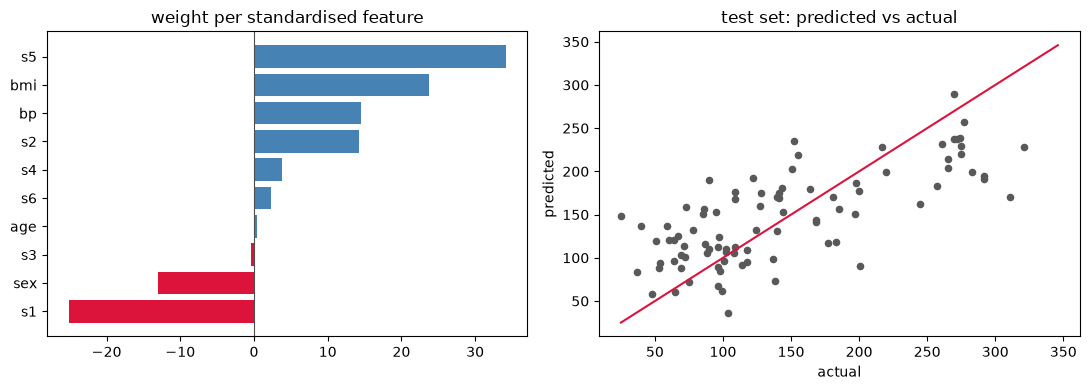

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ordered = sorted(zip(feature_names, descent.weights), key=lambda pair: pair[1])
ax1.barh(
    [name for name, _ in ordered],
    [weight for _, weight in ordered],
    color=["steelblue" if weight > 0 else "crimson" for _, weight in ordered],
)
ax1.axvline(0, color="0.3", lw=0.8)
ax1.set_title("weight per standardised feature")

predicted_test = descent.predict(X_test)
ax2.scatter(y_test, predicted_test, s=20, color="0.35")
limits = [min(y_reg), max(y_reg)]
ax2.plot(limits, limits, color="crimson", lw=1.5)
ax2.set_xlabel("actual"), ax2.set_ylabel("predicted")
ax2.set_title("test set: predicted vs actual")
fig.tight_layout()
plt.show()

## Part 3 — logistic regression

Same fitting function. One change: the linear output goes through a sigmoid on its way out, which
turns it into a probability.

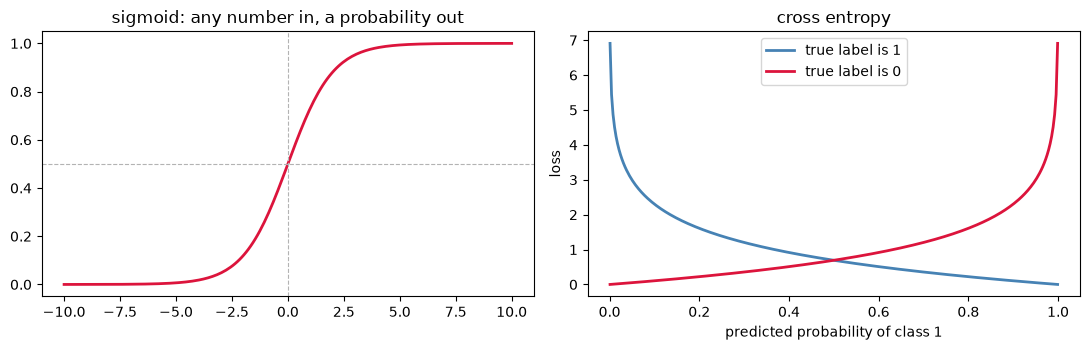

true [1.0, 0.0], predicted [0.99, 0.01] -> cross entropy 0.0101
true [1.0, 0.0], predicted [0.6, 0.4] -> cross entropy 0.5108
true [1.0, 0.0], predicted [0.5, 0.5] -> cross entropy 0.6931
true [1.0, 0.0], predicted [0.1, 0.9] -> cross entropy 2.3026


In [17]:
zs = linspace(-10.0, 10.0, 200)
ps = linspace(0.001, 0.999, 300)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.plot(zs, [sigmoid(z) for z in zs], color="crimson", lw=2)
ax1.axhline(0.5, color="0.7", lw=0.8, ls="--")
ax1.axvline(0, color="0.7", lw=0.8, ls="--")
ax1.set_title("sigmoid: any number in, a probability out")

ax2.plot(ps, [-math.log(p) for p in ps], color="steelblue", lw=2, label="true label is 1")
ax2.plot(ps, [-math.log(1 - p) for p in ps], color="crimson", lw=2, label="true label is 0")
ax2.set_xlabel("predicted probability of class 1"), ax2.set_ylabel("loss")
ax2.set_title("cross entropy"), ax2.legend()
fig.tight_layout()
plt.show()

for truth, guess in (([1.0, 0.0], [0.99, 0.01]), ([1.0, 0.0], [0.6, 0.4]),
                     ([1.0, 0.0], [0.5, 0.5]), ([1.0, 0.0], [0.1, 0.9])):
    print(f"true {truth}, predicted {guess} -> cross entropy {cross_entropy(truth, guess):.4f}")

The right-hand curve is why squared error will not do. As the predicted probability of the truth
goes to zero the loss goes to infinity, so a confident mistake is punished without limit. A coin
flip costs `log 2 = 0.6931`, which is the number to recognise when a classifier has learned
nothing — and the number every fit below starts at, since zero weights predict 0.5 for everything.

### The task

The breast cancer data: 569 tumours, thirty measurements of cell nuclei, and a label saying
malignant or benign.

In [18]:
X_clf, y_clf, clf_names = load_csv("tasks/breast_cancer.csv", "target")

print(f"{len(X_clf)} tumours, {len(clf_names)} features")
print(f"class 1 = benign:    {int(sum(y_clf))} cases")
print(f"class 0 = malignant: {int(len(y_clf) - sum(y_clf))} cases")

train_clf, test_clf = split_indices(len(y_clf))
scaler_clf = Standardiser.fit(take(X_clf, train_clf))
Z_train = scaler_clf.transform(take(X_clf, train_clf))
Z_test = scaler_clf.transform(take(X_clf, test_clf))
c_train, c_test = take(y_clf, train_clf), take(y_clf, test_clf)

print(f"\nmajority-class baseline on the test set: {max(sum(c_test), len(c_test) - sum(c_test)) / len(c_test):.4f}")

569 tumours, 30 features
class 1 = benign:    357 cases
class 0 = malignant: 212 cases

majority-class baseline on the test set: 0.6053


In [19]:
classifier = fit(Z_train, c_train, hypothesis=sigmoid, loss_fn=cross_entropy, lr=0.5, n_iters=3000)
test_probabilities = classifier.model.predict(Z_test)
correct = sum(1 for actual, p in zip(c_test, test_probabilities) if actual == float(p >= 0.5))

print(f"starting loss         {classifier.history[0]:.4f}")
print(f"final training loss   {classifier.history[-1]:.4f}")
print(f"training accuracy     {accuracy(c_train, classifier.model.predict(Z_train)):.4f}")
print(f"test accuracy         {accuracy(c_test, test_probabilities):.4f}   ({correct} of {len(c_test)})")

unscaled = fit(take(X_clf, train_clf), c_train, hypothesis=sigmoid, loss_fn=cross_entropy,
               lr=0.5, n_iters=3000)
unscaled_probabilities = unscaled.model.predict(take(X_clf, test_clf))

print(f"\nwithout standardising the features, everything else identical:")
print(f"starting loss         {unscaled.history[0]:.4f}")
print(f"final training loss   {unscaled.history[-1]:.4f}")
print(f"test accuracy         {accuracy(c_test, unscaled_probabilities):.4f}")

starting loss         0.6931
final training loss   0.0385
training accuracy     0.9912
test accuracy         0.9737   (111 of 114)



without standardising the features, everything else identical:
starting loss         0.6931
final training loss   2.5506
test accuracy         0.9298


Three mistakes in 114, against a majority-class baseline of 61%.

Now look at the unscaled run, and look at the **loss**, not the accuracy. It starts at `log 2` like
every other fit, and after 3000 steps it is far *above* where it started. It has not converged
slowly; it has moved away from the answer and stayed there. With raw features the logits are
enormous, the sigmoid saturates to 0 and 1, and the gradient dies exactly where the model is
confidently wrong.

Its accuracy, meanwhile, still looks respectable. That gap is the lesson: a score can flatter a
model that the loss shows is broken, which is one more reason to report both.

### Seeing the boundary

Thirty dimensions cannot be drawn, so refit on two features only. The model is worse, which is the
honest cost of being able to look at it, but the geometry is the thing to see: the boundary is a
**straight line**, because `σ(z) ≥ 0.5` exactly when `z ≥ 0`, and `z = 0` is a line.

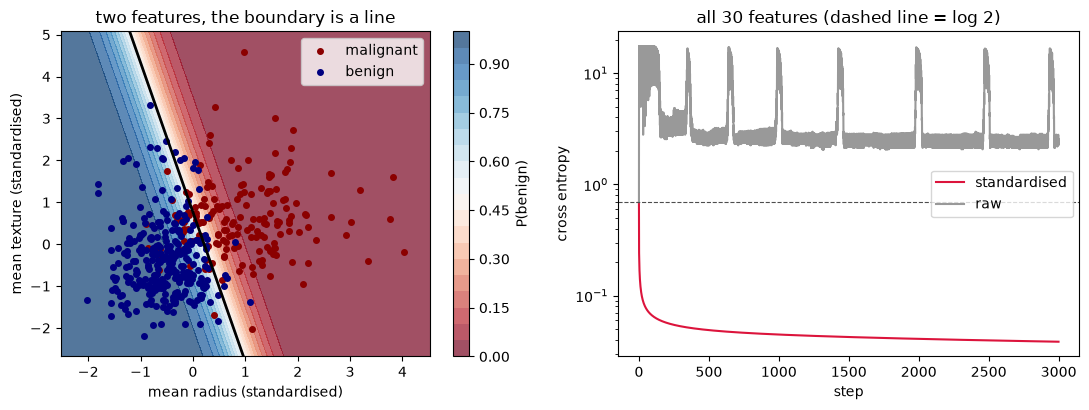

two features only: test accuracy 0.8860
all thirty:        test accuracy 0.9737


In [20]:
pair = [clf_names.index(name) for name in ("mean_radius", "mean_texture")]
P_train = [[row[i] for i in pair] for row in Z_train]
P_test = [[row[i] for i in pair] for row in Z_test]
two_feature = fit(P_train, c_train, hypothesis=sigmoid, loss_fn=cross_entropy,
                  lr=0.5, n_iters=3000).model

radius_axis = linspace(min(r[0] for r in P_train) - 0.5, max(r[0] for r in P_train) + 0.5, 120)
texture_axis = linspace(min(r[1] for r in P_train) - 0.5, max(r[1] for r in P_train) + 0.5, 120)
grid_x = [[gx for gx in radius_axis] for _ in texture_axis]
grid_y = [[gy for _ in radius_axis] for gy in texture_axis]
probability = [[two_feature.predict_one([gx, gy]) for gx in radius_axis] for gy in texture_axis]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

shaded = ax1.contourf(grid_x, grid_y, probability, levels=20, cmap="RdBu", alpha=0.7)
ax1.contour(grid_x, grid_y, probability, levels=[0.5], colors="black", linewidths=2)
for label, colour, name in ((0.0, "darkred", "malignant"), (1.0, "navy", "benign")):
    points = [row for row, actual in zip(P_train, c_train) if actual == label]
    ax1.scatter([p[0] for p in points], [p[1] for p in points], s=16, c=colour, label=name)
ax1.set_xlabel("mean radius (standardised)"), ax1.set_ylabel("mean texture (standardised)")
ax1.set_title("two features, the boundary is a line"), ax1.legend(loc="upper right")
fig.colorbar(shaded, ax=ax1, label="P(benign)")

ax2.plot(classifier.history, color="crimson", label="standardised")
ax2.plot(unscaled.history, color="0.6", label="raw")
ax2.axhline(math.log(2), color="0.3", lw=0.8, ls="--")
ax2.set_yscale("log"), ax2.set_xlabel("step"), ax2.set_ylabel("cross entropy")
ax2.set_title("all 30 features (dashed line = log 2)"), ax2.legend()
fig.tight_layout()
plt.show()

print(f"two features only: test accuracy {accuracy(c_test, two_feature.predict(P_test)):.4f}")
print(f"all thirty:        test accuracy {accuracy(c_test, test_probabilities):.4f}")

## Part 4 — where a straight line runs out

The boundary is a line, so the model can only separate what a line can separate. The smallest
demonstration is the three binary logic functions.

AND  accuracy 1.00   predictions [0.0, 0.002, 0.002, 0.997]


OR   accuracy 1.00   predictions [0.002, 0.999, 0.999, 1.0]


XOR  accuracy 0.50   predictions [0.5, 0.5, 0.5, 0.5]


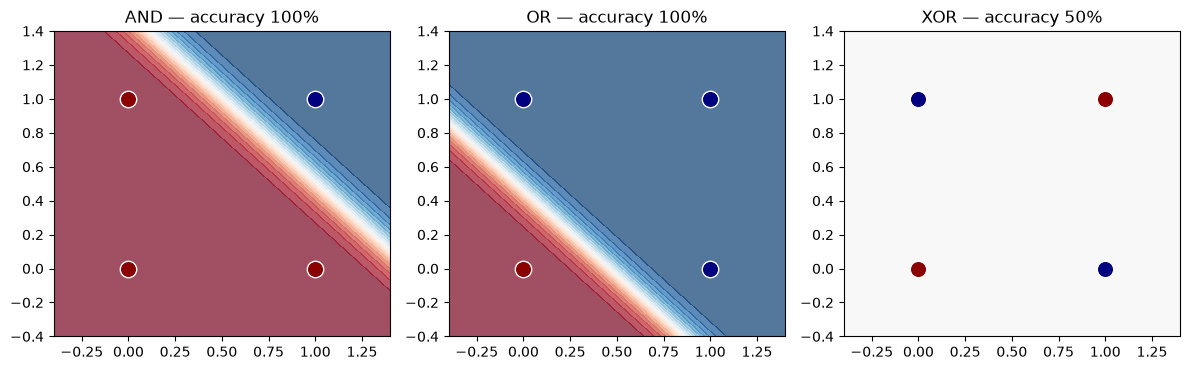

In [21]:
logic_inputs: Matrix = [[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]]
logic_targets = {"AND": [0.0, 0.0, 0.0, 1.0], "OR": [0.0, 1.0, 1.0, 1.0], "XOR": [0.0, 1.0, 1.0, 0.0]}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, targets) in zip(axes, logic_targets.items()):
    gate = fit(logic_inputs, targets, hypothesis=sigmoid, loss_fn=cross_entropy,
               lr=0.5, n_iters=20000).model
    predicted = gate.predict(logic_inputs)
    print(f"{name:<4} accuracy {accuracy(targets, predicted):.2f}   "
          f"predictions {[round(p, 3) for p in predicted]}")

    axis = linspace(-0.4, 1.4, 120)
    gx = [[a for a in axis] for _ in axis]
    gy = [[b for _ in axis] for b in axis]
    surface = [[gate.predict_one([a, b]) for a in axis] for b in axis]
    ax.contourf(gx, gy, surface, levels=20, cmap="RdBu", alpha=0.7, vmin=0, vmax=1)
    for label, colour in ((0.0, "darkred"), (1.0, "navy")):
        points = [row for row, actual in zip(logic_inputs, targets) if actual == label]
        ax.scatter([p[0] for p in points], [p[1] for p in points],
                   s=140, c=colour, edgecolor="white", zorder=3)
    ax.set_title(f"{name} — accuracy {accuracy(targets, predicted):.0%}")
fig.tight_layout()
plt.show()

`AND` and `OR` are learned exactly. `XOR` converges to **0.5 for all four inputs** — the model gives
up and guesses, because no straight line puts the two diagonals on opposite sides.

This is not a failure of gradient descent. It found the best weights available; the best available
is 50%. The hypothesis family cannot express XOR, and no optimiser fixes that. Changing the family
is what the rest of the course is about.

## Where this leaves us

- **One fitting function ran everything above.** Linear and logistic regression differ by whether
  the output passes through a sigmoid; the update rule is identical, and `fit` never learns which
  of the two it is doing.
- **Gradient descent asked nothing of the problem but a derivative**, and matched the closed-form
  answer wherever one existed. That is why it survives into models that have no closed form.
- **Scaling decides whether it works at all.** Ten thousand times the usable learning rate on the
  regression, and on the classification the unscaled run ends worse than it started.
- **A loss and a score answer different questions.** R² near 0.53 and accuracy near 0.97 are both
  measured against a baseline — guess the mean, guess the majority class — and neither means
  anything without it.
- **The model family sets the ceiling.** R² of 0.53 on the diabetes data and 50% on XOR are limits
  of the straight line, not of the fitting.

The thing we have quietly been sloppy about is measurement. We split off a test set **once**, with
one arbitrary seed, and quoted a single number from it. Change `SEED` at the top and rerun: the
diabetes test R² moves between roughly 0.44 and 0.61, and the cancer accuracy between 95% and 100%,
on 114 examples where three mistakes either way moves it by 2.6%. Nothing about the model changed.

What that number is worth, and what to use instead, is next week.